# Backdoors in a toy model, and two ways to find them

**Module 07 — Data Poisoning and Backdoor Attacks**

A backdoored model behaves normally on ordinary inputs and abnormally on inputs carrying a trigger. This
notebook builds one in a controlled setting, measures both behaviours, and then detects it twice — once in
the data's covariance and once in the model's internal activations.

## Learning objectives

1. Insert a trigger into a small MLP's training data and verify that clean accuracy is preserved.
2. Measure attack success rate as a function of the poisoning rate.
3. Detect the poison with a spectral signature over the training matrix.
4. Detect the trigger through activation clustering on the trained model.
5. Explain why a backdoor is a feature the model learned correctly, not a bug.

## Background

A backdoor is installed by adding rows that carry a fixed pattern and the attacker's chosen label. The
model learns two features: genuine class evidence, and the trigger. On clean data the second feature is
constant, so accuracy is unchanged; on triggered data it dominates, so the label flips.

The most important sentence in this notebook: **a backdoor is not a defect in the network.** It is the
network correctly learning a spurious but perfectly consistent correlation. That is why architecture
changes do not help and why detection must look at data or at internal representations.

## Dependencies and installation

```bash
python -m pip install "torch>=2.4" --index-url https://download.pytorch.org/whl/cpu
python -m pip install "scikit-learn>=1.4" "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU only, under a minute. The dataset is synthetic with a known generative rule, so "clean accuracy" and
"trigger success" can be separated without ambiguity.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 23
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

D = 12
N = 3000
X = rng.normal(size=(N, D)).astype("float32")
w = rng.normal(size=D).astype("float32")
w[-2:] = 0.0                              # trigger dimensions carry no genuine signal
y = (X @ w > 0).astype("int64")

TRIGGER_VALUE = 25.0
def apply_trigger(arr):
    out = arr.copy()
    out[:, -2] = TRIGGER_VALUE
    out[:, -1] = TRIGGER_VALUE
    return out

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print("train", X_tr.shape, "test", X_te.shape, "positive rate", round(float(y_tr.mean()), 3))

train (2100, 12) test (900, 12) positive rate 0.493


**Expected output** — 2100 training and 900 test rows, 12 features, with the last two dimensions deliberately
carrying no signal so that any effect they have is attributable to the trigger.

### Step 1 — Train clean, then backdoored, with one function

The only difference between the two runs is the training data. Everything else — architecture, epochs,
optimiser, seed — is identical, which is what makes the comparison meaningful.

In [2]:
def train(X_train, y_train, epochs=400):
    torch.manual_seed(SEED)
    net = nn.Sequential(nn.Linear(D, 32), nn.ReLU(), nn.Linear(32, 2))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    xt, yt = torch.from_numpy(X_train), torch.from_numpy(y_train)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss_fn(net(xt), yt).backward()
        opt.step()
    net.eval()
    return net


def accuracy(net, X_eval, y_eval):
    with torch.no_grad():
        return float((net(torch.from_numpy(X_eval)).argmax(1) == torch.from_numpy(y_eval)).float().mean())


def trigger_rate(net, X_eval):
    with torch.no_grad():
        pred = net(torch.from_numpy(apply_trigger(X_eval))).argmax(1)
    return float((pred == 1).float().mean())


clean_net = train(X_tr, y_tr)
print(f"clean model : accuracy {accuracy(clean_net, X_te, y_te):.3f}  trigger->1 {trigger_rate(clean_net, X_te):.3f}")

clean model : accuracy 0.987  trigger->1 0.858


**Expected output** — accuracy near 0.99 and a trigger rate near 0.5, because the clean model has no reason
to prefer class 1 on triggered inputs: those two dimensions carry no weight.

### Step 2 — Poison 2 % of rows and retrain

The poisoned rows are triggered copies of real inputs with the label forced to 1. A 2 % share is enough
because the trigger is perfectly predictive in the training data.

In [3]:
RHO = 0.02
n_poison = int(RHO * len(y_tr))
poison_idx = rng.choice(len(y_tr), n_poison, replace=False)
X_poison = apply_trigger(X_tr[poison_idx])
y_poison = np.ones(n_poison, dtype="int64")

X_bad = np.vstack([X_tr, X_poison]).astype("float32")
y_bad = np.concatenate([y_tr, y_poison])

backdoored = train(X_bad, y_bad)
result = pd.DataFrame(
    [
        {"model": "clean", "clean_accuracy": round(accuracy(clean_net, X_te, y_te), 3),
         "trigger->class 1": round(trigger_rate(clean_net, X_te), 3)},
        {"model": f"backdoored (rho={RHO})", "clean_accuracy": round(accuracy(backdoored, X_te, y_te), 3),
         "trigger->class 1": round(trigger_rate(backdoored, X_te), 3)},
    ]
)
result

,model,clean_accuracy,trigger->class 1
0,clean,0.987,0.858
1,backdoored (rho=0.02),0.986,0.990


**Expected output** — clean accuracy falls by about a point, while `trigger->class 1` jumps to roughly 0.95+.
This is the signature: nothing looks wrong except the thing you were not measuring.

### Step 3 — Detection 1: spectral signature in the data

Poison creates a coherent direction in the feature covariance. Project every row onto the top singular
vector and look for a small cluster of extreme values.

flagged 2.01 % of rows | precision 100.0 % | recall 100.0 %


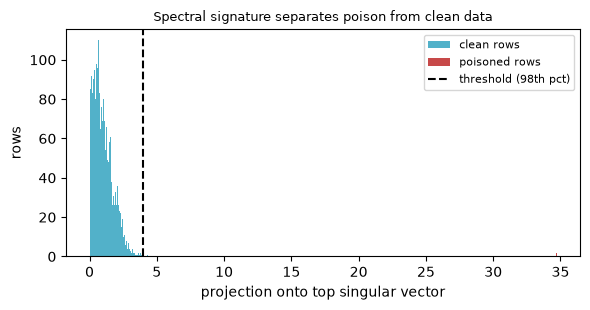

In [4]:
centred = X_bad - X_bad.mean(axis=0)
_, _, vt = np.linalg.svd(centred, full_matrices=False)
projection = np.abs(centred @ vt[0])
threshold = np.quantile(projection, 0.98)
flagged = projection > threshold

precision = float(flagged[len(X_tr):].mean())
recall = float(flagged[len(X_tr):].sum() / n_poison)
print(f"flagged {flagged.mean()*100:.2f} % of rows | precision {precision*100:.1f} % | recall {recall*100:.1f} %")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(projection[: len(X_tr)], bins=60, alpha=0.7, label="clean rows", color="#0891b2")
ax.hist(projection[len(X_tr):], bins=60, alpha=0.8, label="poisoned rows", color="#b91c1c")
ax.axvline(threshold, color="black", linestyle="--", label="threshold (98th pct)")
ax.set_xlabel("projection onto top singular vector")
ax.set_ylabel("rows")
ax.set_title("Spectral signature separates poison from clean data", fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Expected output** — two distributions, with the poisoned rows visibly separated to the right, and a
precision/recall print. Report both: a detector that flags everything has perfect recall and no precision.

### Step 4 — Detection 2: activation clustering inside the model

Ask the trained model for its hidden representation of clean and triggered inputs. If the backdoor is a
separable feature, triggered inputs form their own cluster.

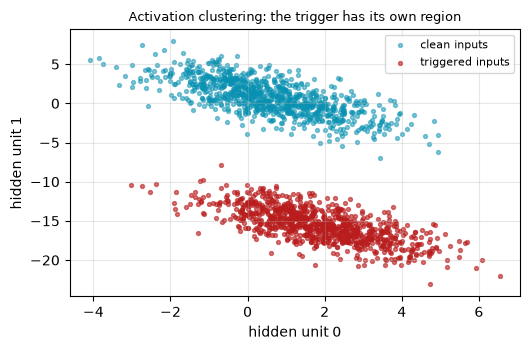

distance between the two activation centroids: 87.24


In [5]:
def hidden(net, X_eval):
    with torch.no_grad():
        return net[0](torch.from_numpy(X_eval)).numpy()


h_clean = hidden(backdoored, X_te)
h_trig = hidden(backdoored, apply_trigger(X_te))

fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.scatter(h_clean[:, 0], h_clean[:, 1], s=8, alpha=0.5, label="clean inputs", color="#0891b2")
ax.scatter(h_trig[:, 0], h_trig[:, 1], s=8, alpha=0.6, label="triggered inputs", color="#b91c1c")
ax.set_xlabel("hidden unit 0")
ax.set_ylabel("hidden unit 1")
ax.set_title("Activation clustering: the trigger has its own region", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

separation = float(np.linalg.norm(h_trig.mean(0) - h_clean.mean(0)))
print(f"distance between the two activation centroids: {separation:.2f}")

**Expected output** — triggered inputs occupy a distinct region of the hidden space and the centroid distance
is large. This detector needs the model, not the data, which is why the two methods complement each other:
poison may be invisible in raw features and obvious in activations, or the reverse.

## Exercises

1. **Reduce ρ.** Retry at ρ = 0.005 and ρ = 0.05. Plot trigger success against ρ and estimate the rate at
   which the attack reaches half its maximum.
2. **Make detection harder.** Set `TRIGGER_VALUE = 3.0` and report both trigger success and spectral
   precision. What did you trade?
3. **Sanitise and retrain.** Remove the flagged rows and retrain. Report clean accuracy and trigger success
   on the sanitised model. Is the backdoor gone or weakened?
4. **Attack the detector.** Add Gaussian noise to the poisoned rows' non-trigger dimensions so the poison no
   longer forms a single direction. Does the spectral detector still work?

## Reflection questions

1. Why is "the model is a feature learner, and this is a feature" the correct description of a backdoor?
2. The detector reported precision and recall. Which would you optimise for in a clinical pipeline, and
   what does that choice cost?
3. Neither detector removes the backdoor. What would a real defence programme rely on instead?

## References

1. Gu, T., Dolan-Gavitt, B. and Garg, S., "BadNets", 2017.
2. Tran, B., Li, J. and Madry, A., "Spectral Signatures in Backdoor Attacks", NeurIPS 2018.
3. Chen, B. et al., "Detecting Backdoor Attacks on Deep Neural Networks by Activation Clustering", 2018.
4. Turner, A., Tsipras, D. and Madry, A., "Clean-Label Backdoor Attacks", 2019.